In [ ]:
# Install libraries on the uv venv
!uv add pandas
!uv add numpy
!uv add matplotlib
!uv add folium

# EDA EcoBicis — Octubre 2026


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from branca.colormap import LinearColormap
from matplotlib.colors import to_hex

from datasetting import DATA_DIR, DIAS, cargar_datos, filtrar_validos, uso_por_estacion, aplicar_estilo

# Estilo de las gráficas: paleta categórica fija y ejes discretos
aplicar_estilo()

## Carga y limpieza de datos
`cargar_datos()` (en `datasetting.py`) lee los CSV, une fecha y hora en datetime, corrige las estaciones con número doble (`235-236` → `235`) y agrega las variables derivadas.
Aquí se cargan **todos** los viajes (`validos=False`) del archivo de octubre (`public_data_web_2026-10.csv`) para revisar la calidad de los datos antes de filtrar.

In [2]:
viajes, estaciones = cargar_datos(validos=False, ruta_viajes=DATA_DIR / "public_data_web_2026-10.csv")
print(f"{len(viajes):,} viajes, {len(estaciones):,} estaciones")
viajes.head()

1,599,384 viajes, 677 estaciones


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
0,M,22,4027652,282,91,2026-09-30 23:24:17,2026-10-01 00:00:02,35.750000,2026-09-30,23,2,False,False,16-24,Benito Juarez,Cuauhtemoc,4.970302,8.341766
1,F,32,3155801,375,624,2026-09-30 23:52:05,2026-10-01 00:00:03,7.966667,2026-09-30,23,2,False,False,25-34,Benito Juarez,Benito Juarez,1.119996,8.435118
2,F,25,3926144,2,112,2026-09-30 23:44:54,2026-10-01 00:00:14,15.333333,2026-09-30,23,2,False,False,25-34,Cuauhtemoc,Cuauhtemoc,2.058975,8.056860
3,M,24,2386167,563,561,2026-09-30 23:57:33,2026-10-01 00:00:24,2.850000,2026-09-30,23,2,False,False,16-24,Cuauhtemoc,Cuauhtemoc,0.507460,10.683376
4,M,41,2117323,114,56,2026-09-30 23:45:41,2026-10-01 00:00:27,14.766667,2026-09-30,23,2,False,False,35-44,Cuauhtemoc,Cuauhtemoc,1.824214,7.412156


In [3]:
viajes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599384 entries, 0 to 1599383
Data columns (total 18 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Genero_Usuario         1599384 non-null  category      
 1   Edad_Usuario           1599354 non-null  Int64         
 2   Bici                   1599384 non-null  int64         
 3   Ciclo_Estacion_Retiro  1599384 non-null  Int64         
 4   Ciclo_Estacion_Arribo  1599384 non-null  Int64         
 5   Fecha_Hora_Retiro      1599384 non-null  datetime64[ns]
 6   Fecha_Hora_Arribo      1599384 non-null  datetime64[ns]
 7   Duracion_min           1599384 non-null  float64       
 8   Fecha                  1599384 non-null  datetime64[ns]
 9   Hora                   1599384 non-null  int32         
 10  Dia_Semana             1599384 non-null  int32         
 11  Fin_de_Semana          1599384 non-null  bool          
 12  Viaje_Circular         15993

## Catálogo de estaciones
Indexado por `num_cicloe`; la columna `Estacion` es `calle_prin y calle_secu`.

In [4]:
estaciones

,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus,Estacion
num_cicloe,,,,,,,,,
1,Rio Sena,Rio Balsas,Cuauhtemoc,Cuauhtemoc,19.433590,-99.167819,Arroyo,Instalada,Rio Sena y Rio Balsas
2,Rio Guadalquivir,Rio Nazas,Cuauhtemoc,Cuauhtemoc,19.430623,-99.171231,Arroyo,Instalada,Rio Guadalquivir y Rio Nazas
3,Av. Paseo de la Reforma,Av. Insurgentes,Tabacalera,Cuauhtemoc,19.431630,-99.158547,Banqueta,Instalada,Av. Paseo de la Reforma y Av. Insurgentes
4,Rio Nilo,Rio Panuco,Cuauhtemoc,Cuauhtemoc,19.428491,-99.171693,Arroyo,Instalada,Rio Nilo y Rio Panuco
5,Rio Panuco,Rio Tiber,Cuauhtemoc,Cuauhtemoc,19.429804,-99.169451,Arroyo,Instalada,Rio Panuco y Rio Tiber
...,...,...,...,...,...,...,...,...,...
707,Irlanda,Av. Division del Norte,Parque San Andres,Coyoacan,19.348076,-99.149060,Arroyo,Instalada,Irlanda y Av. Division del Norte
708,Irlanda,Canada,Parque San Andres,Coyoacan,19.346489,-99.145828,Arroyo,Instalada,Irlanda y Canada
709,Inglaterra,Antigua Taxque�a,Parque San Andres,Coyoacan,19.344271,-99.149973,Arroyo,Instalada,Inglaterra y Antigua Taxque�a


In [5]:
estaciones.info()

<class 'pandas.core.frame.DataFrame'>
Index: 677 entries, 1 to 711
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   calle_prin  677 non-null    object 
 1   calle_secu  677 non-null    object 
 2   colonia     677 non-null    object 
 3   alcaldia    677 non-null    object 
 4   latitud     677 non-null    float64
 5   longitud    677 non-null    float64
 6   sitio_de_e  677 non-null    object 
 7   estatus     677 non-null    object 
 8   Estacion    677 non-null    object 
dtypes: float64(2), object(7)
memory usage: 69.7+ KB


## Variables derivadas
Ya vienen calculadas desde `datasetting.agregar_columnas`: duración, fecha, hora, día de la semana, fin de semana, viajes circulares (misma estación de retiro y arribo), rango de edad, alcaldías de origen y destino, distancia y velocidad.

In [6]:
cols_derivadas = ["Duracion_min", "Fecha", "Hora", "Dia_Semana", "Fin_de_Semana", "Viaje_Circular",
                  "Rango_Edad", "Alcaldia_Retiro", "Alcaldia_Arribo", "Distancia_km", "Velocidad_kmh"]
viajes[cols_derivadas].head()

,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
0,35.750000,2026-09-30,23,2,False,False,16-24,Benito Juarez,Cuauhtemoc,4.970302,8.341766
1,7.966667,2026-09-30,23,2,False,False,25-34,Benito Juarez,Benito Juarez,1.119996,8.435118
2,15.333333,2026-09-30,23,2,False,False,25-34,Cuauhtemoc,Cuauhtemoc,2.058975,8.056860
3,2.850000,2026-09-30,23,2,False,False,16-24,Cuauhtemoc,Cuauhtemoc,0.507460,10.683376
4,14.766667,2026-09-30,23,2,False,False,35-44,Cuauhtemoc,Cuauhtemoc,1.824214,7.412156


In [7]:
viajes.describe()

,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Distancia_km,Velocidad_kmh
count,1599354.0,1.599384e+06,1599384.0,1599384.0,1599384,1599384,1.599384e+06,1599384,1.599384e+06,1.599384e+06,1.599384e+06,1.599384e+06
mean,34.831974,5.475471e+06,292.231262,289.97315,2026-10-16 19:42:05.389267456,2026-10-16 19:58:12.619696896,1.612051e+01,2026-10-16 05:19:31.224921600,1.388029e+01,2.802360e+00,1.866343e+00,8.075796e+00
min,16.0,2.000461e+06,1.0,1.0,2026-02-14 17:52:04,2026-10-01 00:00:02,3.000000e-01,2026-02-14 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,28.0,3.747516e+06,112.0,109.0,2026-10-08 18:07:57.750000128,2026-10-08 18:25:06,7.300000e+00,2026-10-08 00:00:00,1.000000e+01,1.000000e+00,8.757722e-01,6.380521e+00
50%,33.0,5.499462e+06,255.0,254.0,2026-10-16 16:11:34,2026-10-16 16:28:02,1.223333e+01,2026-10-16 00:00:00,1.400000e+01,3.000000e+00,1.484673e+00,8.382852e+00
75%,40.0,7.211923e+06,480.0,480.0,2026-10-24 12:47:02.500000,2026-10-24 13:02:48.249999872,2.048333e+01,2026-10-24 00:00:00,1.800000e+01,4.000000e+00,2.496910e+00,1.017531e+01
max,130.0,8.999708e+06,711.0,711.0,2026-10-31 23:56:08,2026-10-31 23:59:54,3.514386e+05,2026-10-31 00:00:00,2.300000e+01,6.000000e+00,1.359759e+01,2.833328e+01
std,9.927206,2.017053e+06,208.242803,209.310981,NaN,NaN,3.112981e+02,NaN,4.682842e+00,1.846942e+00,1.398466e+00,3.212045e+00


## Calidad de los datos

In [8]:
dur = viajes["Duracion_min"]

print("=" * 42)
print("Nulos por columna:")
print(viajes.isna().sum()[lambda s: s > 0]) # TODOS LOS NULOS EN EL DF
print("=" * 42)

print("Filas duplicadas:", viajes.duplicated().sum())
print("Géneros:", viajes["Genero_Usuario"].value_counts().to_dict())

print(f"Duración < 1 min: {(dur < 1).sum():>6}")
print(f"Duración > 3 h:   {(dur > 180).sum():>6}")
print(f"Duración > 24 h:  {(dur > 1440).sum():>6}   (max: {dur.max() / 1440:.0f} días)")
print(f"Retiros antes de octubre: {(viajes['Fecha_Hora_Retiro'] < '2026-10-01').sum()}")

Nulos por columna:
Edad_Usuario    30
Rango_Edad      36
dtype: int64
Filas duplicadas: 0
Géneros: {'M': 1087453, 'F': 444420, '?': 39868, 'O': 27643}
Duración < 1 min:    232
Duración > 3 h:      847
Duración > 24 h:      30   (max: 244 días)
Retiros antes de octubre: 147


In [9]:
ids_catalogo = set(estaciones.index)
ids_viajes = set(viajes["Ciclo_Estacion_Retiro"]) | set(viajes["Ciclo_Estacion_Arribo"])

print("Estaciones en viajes que no están en el catálogo:", sorted(ids_viajes - ids_catalogo))
print("Estaciones (num) del catálogo sin ningún viaje:", sorted(ids_catalogo - ids_viajes))

# El CSV de estaciones trae ñ y acentos perdidos, guardados como "�"
cols_texto = ["calle_prin", "calle_secu", "colonia", "alcaldia", "sitio_de_e"]
con_error = estaciones[cols_texto].apply(lambda col: col.str.contains("�", regex=False)).any(axis=1)
print("Filas del catálogo con caracteres perdidos (�):", con_error.sum())
estaciones.loc[con_error, cols_texto].head()

Estaciones en viajes que no están en el catálogo: []
Estaciones (num) del catálogo sin ningún viaje: [np.int64(699)]
Filas del catálogo con caracteres perdidos (�): 34


,calle_prin,calle_secu,colonia,alcaldia,sitio_de_e
num_cicloe,,,,,
54,Parque Espa�a,Sonora,Condesa,Cuauhtemoc,Arroyo
58,Parque Espa�a,Juan de la Barrera,Condesa,Cuauhtemoc,Banqueta
83,Alfonso Reyes,Nuevo Le�n,Hipodromo,Cuauhtemoc,Arroyo
97,Republica de Salvador,Jose Maria Pino Suarez,Centro,Cuauhtemoc,Camell�n
134,Alvaro Obregon,Orizaba,Roma Norte,Cuauhtemoc,Camell�n


**Hallazgos**
- 30 viajes duran más de 24 h (el más largo ~244 días, con retiros desde febrero): bicis no devueltas o errores de registro.
- 232 viajes duran menos de 1 min: probablemente retiros cancelados.
- 147 viajes tienen retiro antes de octubre (principalmente de la noche del 30 de septiembre con arribo en octubre).
- 39,868 viajes tienen género `?` (sin dato), 30 no tienen edad y 6 registran edad `130` (fuera de los rangos `16-100`).
- Todas las estaciones de los viajes existen en el catálogo; la 699 no tiene viajes en octubre.
- 34 estaciones tienen ñ/acentos perdidos (`La Coru�a`). El `�` ya viene en el archivo, así que no se recupera leyendo con otro encoding.

Para el resto del análisis se usan los viajes retirados en octubre con duración entre 1 min y 3 h.

### Viajes validos df

In [10]:
# Viajes validos (entre 1 min y 3 horas, en octubre 2026).
viajes_validos = filtrar_validos(viajes, desde="2026-10-01", hasta="2026-11-01")
print("Viajes validos:")
print(f"{len(viajes_validos):,} de {len(viajes):,} viajes ({len(viajes_validos) / len(viajes):.2%})")

viajes_validos.head()

Viajes validos:
1,598,169 de 1,599,384 viajes (99.92%)


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
0,M,41,3476108,496,497,2026-10-01 00:00:06,2026-10-01 00:04:08,4.033333,2026-10-01,0,3,False,False,35-44,Miguel Hidalgo,Miguel Hidalgo,0.405858,6.037551
1,F,36,2184182,553,546,2026-10-01 00:00:41,2026-10-01 00:05:05,4.400000,2026-10-01,0,3,False,False,35-44,Cuauhtemoc,Cuauhtemoc,0.797058,10.868972
2,F,28,8093296,181,167,2026-10-01 00:00:59,2026-10-01 00:05:16,4.283333,2026-10-01,0,3,False,False,25-34,Cuauhtemoc,Miguel Hidalgo,0.515454,7.220365
3,M,23,5152053,181,172,2026-10-01 00:00:48,2026-10-01 00:06:26,5.633333,2026-10-01,0,3,False,False,16-24,Cuauhtemoc,Miguel Hidalgo,0.773696,8.240546
4,F,29,7064538,511,507,2026-10-01 00:00:50,2026-10-01 00:06:47,5.950000,2026-10-01,0,3,False,False,25-34,Azcapotzalco,Miguel Hidalgo,0.745162,7.514236


## Perfil de usuarios

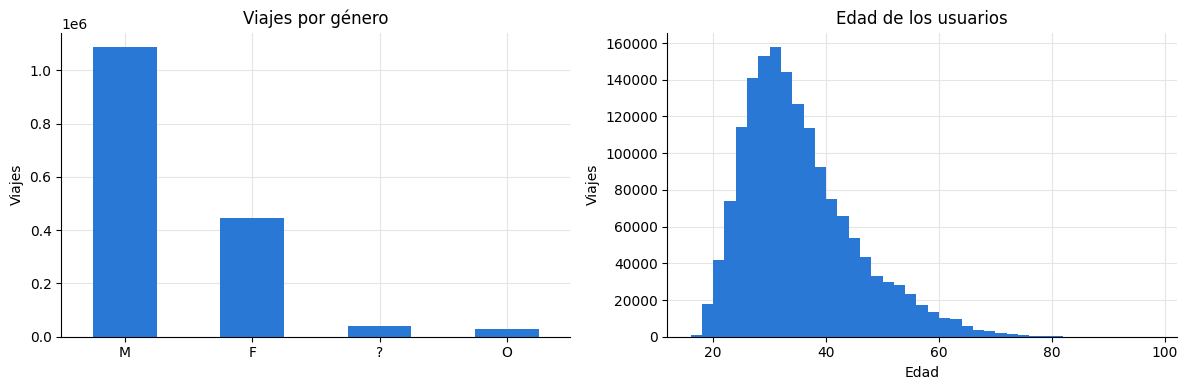

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Genero_Usuario"].value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Viajes por género", xlabel="", ylabel="Viajes")

viajes_validos["Edad_Usuario"].plot.hist(bins=range(16, 100, 2), ax=axes[1])
axes[1].set(title="Edad de los usuarios", xlabel="Edad", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [12]:
rango_edad = pd.cut(
    viajes_validos["Edad_Usuario"],
    bins=[15, 24, 34, 44, 54, 64, 100],
    labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
# Proporción de cada rango de edad dentro de cada género
pd.crosstab(rango_edad, viajes_validos["Genero_Usuario"], normalize="columns").round(3)

Genero_Usuario,?,F,M,O
Edad_Usuario,,,,
16-24,0.151,0.122,0.113,0.102
25-34,0.553,0.508,0.427,0.493
35-44,0.214,0.245,0.284,0.300
45-54,0.058,0.088,0.118,0.081
55-64,0.020,0.031,0.045,0.020
65+,0.003,0.006,0.012,0.004


## Patrones temporales
Los promedios se dividen entre el número de días de cada tipo (octubre 2026 tiene 22 días entre semana y 9 de fin de semana).

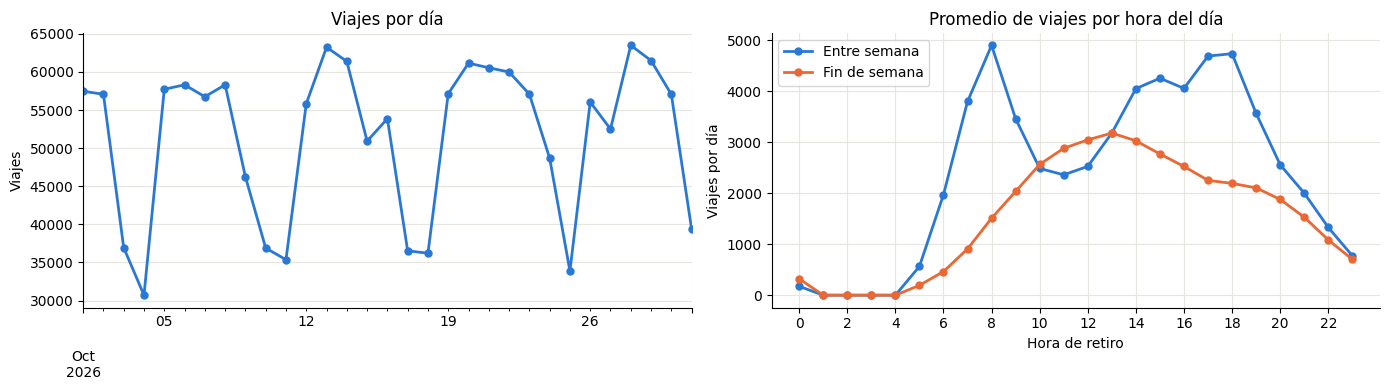

In [13]:
dias_por_tipo = viajes_validos.groupby("Fin_de_Semana")["Fecha"].nunique()
# Ecobici no opera de 1:00 a 4:59, así que esas horas se rellenan con 0
por_hora = viajes_validos.groupby(["Hora", "Fin_de_Semana"]).size().unstack().reindex(range(24), fill_value=0) / dias_por_tipo
por_hora.columns = ["Entre semana", "Fin de semana"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

viajes_validos.groupby("Fecha").size().plot(ax=axes[0], marker="o")
axes[0].set(title="Viajes por día", xlabel="", ylabel="Viajes")

por_hora.plot(ax=axes[1], marker="o")
axes[1].set(title="Promedio de viajes por hora del día", xlabel="Hora de retiro", ylabel="Viajes por día")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

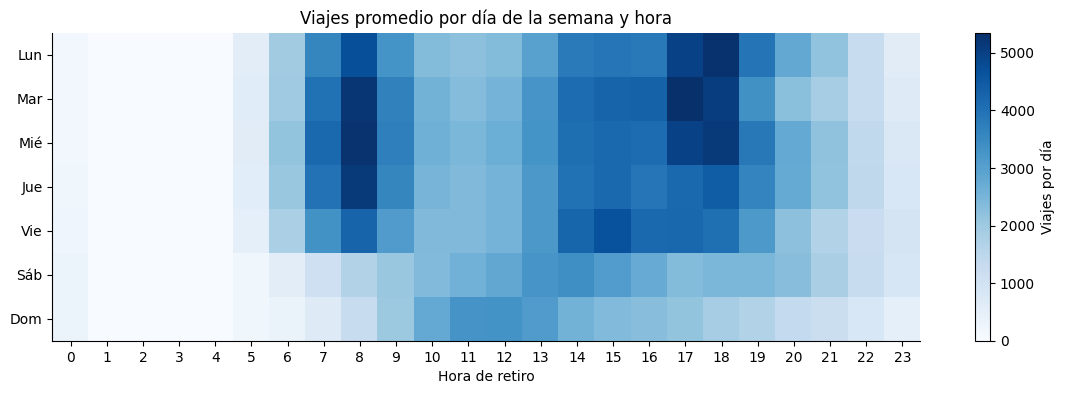

In [14]:
dias_por_semana = viajes_validos.groupby("Dia_Semana")["Fecha"].nunique()
calor = (pd.crosstab(viajes_validos["Dia_Semana"], viajes_validos["Hora"])
         .reindex(columns=range(24), fill_value=0)
         .div(dias_por_semana, axis=0))

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(calor, cmap="Blues", aspect="auto")
ax.set_yticks(range(7), DIAS)
ax.set_xticks(range(24))
ax.grid(False)
ax.set(title="Viajes promedio por día de la semana y hora", xlabel="Hora de retiro")
fig.colorbar(im, ax=ax, label="Viajes por día")
plt.show()

## Duración de los viajes

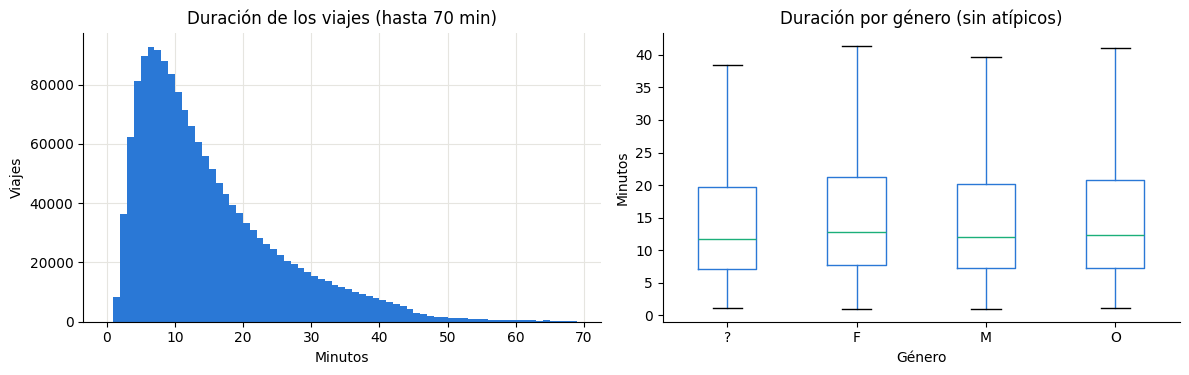

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

viajes_validos["Duracion_min"].plot.hist(bins=range(0, 70), ax=axes[0])
axes[0].set(title="Duración de los viajes (hasta 70 min)", xlabel="Minutos", ylabel="Viajes")

viajes_validos.boxplot(column="Duracion_min", by="Genero_Usuario", ax=axes[1], showfliers=False, grid=False)
axes[1].set(title="Duración por género (sin atípicos)", xlabel="Género", ylabel="Minutos")
fig.suptitle("")

plt.tight_layout()
plt.show()

In [16]:
(viajes_validos.groupby("Fin_de_Semana")["Duracion_min"]
    .describe(percentiles=[0.5, 0.9]).round(1)
    .rename(index={False: "Entre semana", True: "Fin de semana"}))

,count,mean,std,min,50%,90%,max
Fin_de_Semana,,,,,,,
Entre semana,1263639.0,15.0,11.0,1.0,12.0,29.5,180.0
Fin de semana,334530.0,17.6,14.5,1.0,13.3,36.0,179.5


## Estaciones
`Neto` = arribos − retiros. Negativo: la estación se vacía; positivo: se llena (candidatas a rebalanceo).

In [17]:
nombre_estacion = estaciones["Estacion"]

uso = uso_por_estacion(viajes_validos, estaciones)

print(f"Viajes circulares (misma estación): {viajes_validos['Viaje_Circular'].mean():.2%}")
uso.sort_values("Total", ascending=False).head(10)

Viajes circulares (misma estación): 2.70%


,Estacion,Retiros,Arribos,Total,Neto
num_cicloe,,,,,
271,Jesus Garcia y Carlos J. Meneses,11006,20374,31380,9368
548,Doctor Mariano Azuela y Jose Antonio Alzate,9205,9940,19145,735
27,Av. Paseo de la Reforma y Havre,9148,9159,18307,11
64,Sonora y Amsterdam,8199,8747,16946,548
38,Cozumel y Puebla,8498,8304,16802,-194
555,Av. Ribera de San Cosme y Av. Insurgentes Centro,8132,7642,15774,-490
194,Circuito Mahatma Gandhi y Av. Paseo de la Reforma,7655,7611,15266,-44
43,Juarez y Doctor Mora,7359,7817,15176,458
18,Av. Paseo de la Reforma y Rio Rhin,7348,7686,15034,338


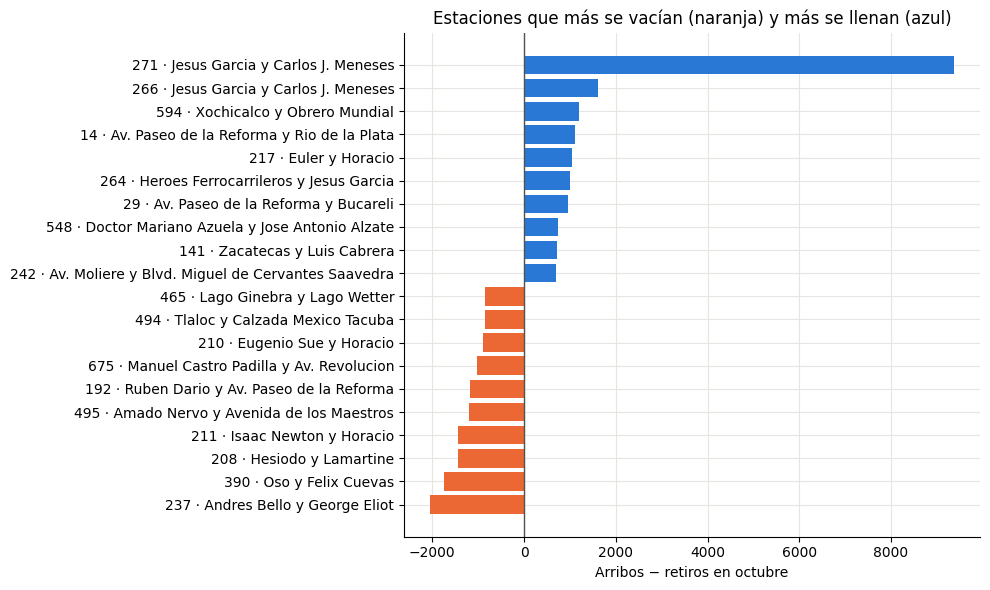

In [18]:
extremos = pd.concat([uso.nsmallest(10, "Neto"), uso.nlargest(10, "Neto")]).sort_values("Neto")
etiquetas = [f"{i} · {n}" for i, n in zip(extremos.index, extremos["Estacion"])]
colores = np.where(extremos["Neto"] < 0, "#eb6834", "#2a78d6")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(etiquetas, extremos["Neto"], color=colores)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Estaciones que más se vacían (naranja) y más se llenan (azul)", xlabel="Arribos − retiros en octubre")
plt.tight_layout()
plt.show()

In [19]:
rutas = (
    viajes_validos[~viajes_validos["Viaje_Circular"]]
    .groupby(["Ciclo_Estacion_Retiro", "Ciclo_Estacion_Arribo"]).size()
    .nlargest(15).rename("Viajes").reset_index()
)
rutas["Origen"] = rutas["Ciclo_Estacion_Retiro"].map(nombre_estacion)
rutas["Destino"] = rutas["Ciclo_Estacion_Arribo"].map(nombre_estacion)
rutas

,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Viajes,Origen,Destino
0,621,618,733,Lago Poniente y Calzada de Tlalpan,Bartolome R. Salido y Edzna
1,548,498,641,Doctor Mariano Azuela y Jose Antonio Alzate,Avenida de los Maestros y Plan de Agua Prieta
2,494,486,610,Tlaloc y Calzada Mexico Tacuba,Izcoatl y Circuito Interior Melchor Ocampo
3,495,499,596,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Calzada de los Gallos
4,495,498,582,Amado Nervo y Avenida de los Maestros,Avenida de los Maestros y Plan de Agua Prieta
5,618,621,562,Bartolome R. Salido y Edzna,Lago Poniente y Calzada de Tlalpan
6,498,548,550,Avenida de los Maestros y Plan de Agua Prieta,Doctor Mariano Azuela y Jose Antonio Alzate
7,174,111,540,Joaquin Garcia Icazbalceta y Ignacio Manuel Al...,Guillermo Prieto y Joaquin Velazquez de Leon
8,208,242,532,Hesiodo y Lamartine,Av. Moliere y Blvd. Miguel de Cervantes Saavedra
9,539,548,523,Naranjo y Av. Ricardo Flores Mag�n,Doctor Mariano Azuela y Jose Antonio Alzate


## Análisis geográfico
La distancia es en línea recta entre estaciones (cota inferior de la distancia real recorrida).

In [20]:
coords = estaciones
mapa = coords.join(uso["Total"]).fillna({"Total": 0})


def mapa_estaciones(mapa, titulo, log=False):
    """Mapa interactivo (zoom, arrastre, hover) de las estaciones sobre un mapa de calles."""
    mapa = mapa.reset_index()
    mapa["Estacion"] = mapa["calle_prin"] + " y " + mapa["calle_secu"]
    sin_viajes = mapa[mapa["Total"] == 0]
    con_viajes = mapa[mapa["Total"] > 0].sort_values("Total")  # las más usadas se dibujan encima

    valor = np.log10(con_viajes["Total"]) if log else con_viajes["Total"]
    azules = [to_hex(c) for c in plt.cm.Blues(np.linspace(0.35, 1, 6))]  # sin los azules casi blancos, que no se ven sobre el mapa
    escala = LinearColormap(azules, vmin=valor.min(), vmax=valor.max(),
                            caption="Retiros + arribos, log10 (1 = 10, 2 = 100, 3 = 1,000)" if log else "Retiros + arribos")

    fig = folium.Figure(height=700)
    m = folium.Map(tiles="OpenStreetMap", zoom_snap=0.25).add_to(fig)
    m.fit_bounds([[mapa["latitud"].min(), mapa["longitud"].min()], [mapa["latitud"].max(), mapa["longitud"].max()]])

    for fila, v in zip(con_viajes.itertuples(), valor):
        folium.CircleMarker(
            [fila.latitud, fila.longitud], radius=4, weight=0.5, color="#52514e",
            fill=True, fill_color=escala(v), fill_opacity=0.9,
            tooltip=f"<b>{fila.Estacion}</b><br>Estación {fila.num_cicloe} · {fila.colonia}, {fila.alcaldia}"
                    f"<br>Retiros + arribos: {fila.Total:,.0f}",
        ).add_to(m)
    for fila in sin_viajes.itertuples():
        folium.CircleMarker(
            [fila.latitud, fila.longitud], radius=3, weight=1, color="#8a8984", fill=False,
            tooltip=f"<b>{fila.Estacion}</b><br>Estación {fila.num_cicloe} · Sin viajes",
        ).add_to(m)

    escala.add_to(m)
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:absolute; top:10px; left:55px; z-index:1000; background:white; padding:4px 10px;'
        f' border-radius:4px; box-shadow:0 1px 4px rgba(0,0,0,.3); font:14px sans-serif">{titulo}</div>'))
    return fig


mapa_estaciones(mapa, "Estaciones Ecobici por número de viajes (octubre)")

#### Domingo: Analisis geografico

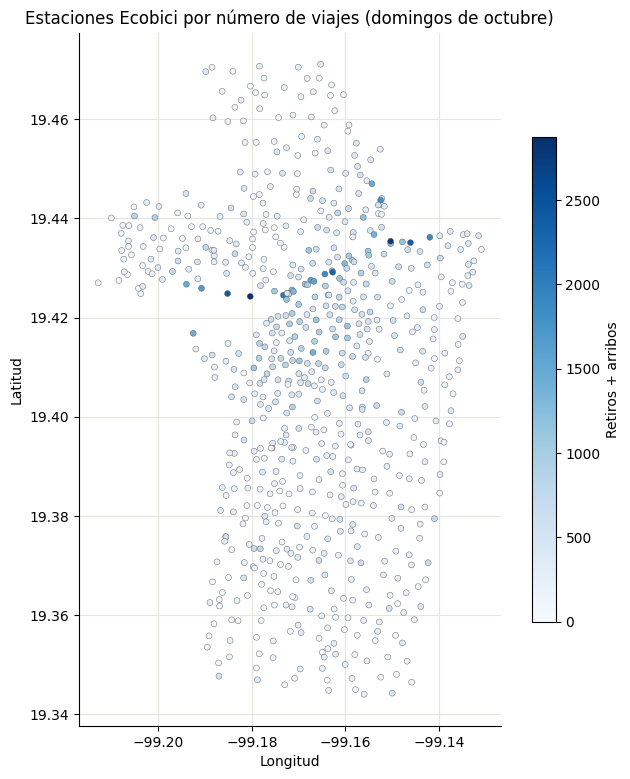

In [21]:
viajes_validos_dom = viajes_validos[viajes_validos["Dia_Semana"] == 6]

uso_dom = uso_por_estacion(viajes_validos_dom, estaciones)

mapa_dom = coords.join(uso_dom["Total"]).fillna({"Total": 0})

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(mapa_dom["longitud"], mapa_dom["latitud"], c=mapa_dom["Total"], cmap="Blues",
                s=18, edgecolors="#52514e", linewidths=0.3)
ax.set_aspect(1 / np.cos(np.radians(mapa_dom["latitud"].mean())))
ax.set(title="Estaciones Ecobici por número de viajes (domingos de octubre)", xlabel="Longitud", ylabel="Latitud")
fig.colorbar(sc, ax=ax, label="Retiros + arribos", shrink=0.7)
plt.show()

In [22]:
viajes_validos_dom = viajes_validos[viajes_validos["Dia_Semana"] == 6]

uso_dom = uso_por_estacion(viajes_validos_dom, estaciones)

mapa_dom = coords.join(uso_dom["Total"]).fillna({"Total": 0})

# Escala logarítmica: unas pocas estaciones concentran muchos viajes en domingo
mapa_estaciones(mapa_dom, "Estaciones Ecobici por número de viajes (domingos de octubre)", log=True)

In [23]:
# Distancia_km y Velocidad_kmh ya vienen calculadas (ver datasetting.haversine_km)
no_circulares = viajes_validos[~viajes_validos["Viaje_Circular"]]
print(f"Viajes a más de 30 km/h (sospechosos): {(no_circulares['Velocidad_kmh'] > 30).sum()}")
no_circulares[["Distancia_km", "Velocidad_kmh"]].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(2)

Viajes a más de 30 km/h (sospechosos): 0


,Distancia_km,Velocidad_kmh
count,1555017.00,1555017.00
mean,1.92,8.30
std,1.38,2.95
min,0.00,0.00
5%,0.45,2.75
50%,1.52,8.48
95%,4.71,12.88
99%,6.56,14.93
max,13.60,28.33


In [24]:
vel_alta = no_circulares.loc[(no_circulares['Velocidad_kmh'] >= 20)].copy()
vel_alta = vel_alta.sort_values(by='Velocidad_kmh')
vel_alta

,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Ciclo_Estacion_Arribo,Fecha_Hora_Retiro,Fecha_Hora_Arribo,Duracion_min,Fecha,Hora,Dia_Semana,Fin_de_Semana,Viaje_Circular,Rango_Edad,Alcaldia_Retiro,Alcaldia_Arribo,Distancia_km,Velocidad_kmh
1235121,M,25,3072386,286,61,2026-10-25 06:53:23,2026-10-25 06:59:16,5.883333,2026-10-25,6,6,True,False,25-34,Miguel Hidalgo,Cuauhtemoc,1.961534,20.004308
975065,M,21,6238679,227,237,2026-10-20 14:40:19,2026-10-20 14:44:51,4.533333,2026-10-20,14,1,False,False,16-24,Miguel Hidalgo,Miguel Hidalgo,1.511817,20.009349
1328122,M,27,8174583,390,334,2026-10-27 07:30:10,2026-10-27 07:34:39,4.483333,2026-10-27,7,1,False,False,25-34,Benito Juarez,Benito Juarez,1.495387,20.012618
1354435,M,21,7902414,31,685,2026-10-27 14:36:02,2026-10-27 15:03:59,27.950000,2026-10-27,14,1,False,False,16-24,Cuauhtemoc,Alvaro Obregon,9.323491,20.014650
1328751,F,43,2551968,455,250,2026-10-27 07:37:44,2026-10-27 07:45:10,7.433333,2026-10-27,7,1,False,False,35-44,Miguel Hidalgo,Miguel Hidalgo,2.482151,20.035298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375013,M,27,3981487,487,494,2026-10-08 11:54:19,2026-10-08 11:55:34,1.250000,2026-10-08,11,3,False,False,25-34,Miguel Hidalgo,Miguel Hidalgo,0.503703,24.177736
347156,M,32,5806476,589,708,2026-10-07 19:10:10,2026-10-07 19:24:21,14.183333,2026-10-07,19,2,False,False,25-34,Benito Juarez,Coyoacan,5.855284,24.769709
613113,M,22,6217079,494,487,2026-10-13 13:47:21,2026-10-13 13:48:34,1.216667,2026-10-13,13,1,False,False,16-24,Miguel Hidalgo,Miguel Hidalgo,0.503703,24.840140
342766,M,41,6259758,487,494,2026-10-07 18:18:29,2026-10-07 18:19:33,1.066667,2026-10-07,18,2,False,False,35-44,Miguel Hidalgo,Miguel Hidalgo,0.503703,28.333285


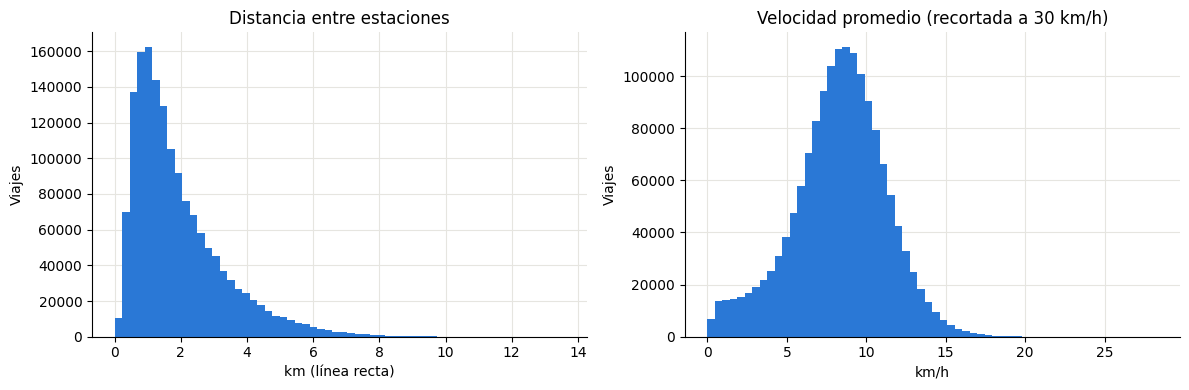

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

no_circulares["Distancia_km"].plot.hist(bins=60, ax=axes[0])
axes[0].set(title="Distancia entre estaciones", xlabel="km (línea recta)", ylabel="Viajes")

no_circulares["Velocidad_kmh"].clip(upper=30).plot.hist(bins=60, ax=axes[1])
axes[1].set(title="Velocidad promedio (recortada a 30 km/h)", xlabel="km/h", ylabel="Viajes")

plt.tight_layout()
plt.show()

In [26]:
por_alcaldia = pd.DataFrame({
    "Estaciones": estaciones["alcaldia"].value_counts(),
    "Retiros": viajes_validos["Alcaldia_Retiro"].value_counts(),
})
por_alcaldia["Retiros_por_estacion"] = (por_alcaldia["Retiros"] / por_alcaldia["Estaciones"]).round(0)
por_alcaldia.sort_values("Retiros", ascending=False)

,Estaciones,Retiros,Retiros_por_estacion
Cuauhtemoc,243,788742,3246.0
Benito Juarez,213,376420,1767.0
Miguel Hidalgo,139,340591,2450.0
Coyoacan,37,37348,1009.0
Azcapotzalco,28,33054,1180.0
Alvaro Obregon,17,22014,1295.0


In [27]:
# Proporción de destinos para cada alcaldía de origen
pd.crosstab(
    viajes_validos["Alcaldia_Retiro"].rename("Origen"),
    viajes_validos["Alcaldia_Arribo"].rename("Destino"),
    normalize="index",
).round(3)

Destino,Alvaro Obregon,Azcapotzalco,Benito Juarez,Coyoacan,Cuauhtemoc,Miguel Hidalgo
Origen,,,,,,
Alvaro Obregon,0.329,0.000,0.394,0.163,0.092,0.022
Azcapotzalco,0.000,0.460,0.005,0.000,0.182,0.353
Benito Juarez,0.021,0.000,0.738,0.038,0.162,0.041
Coyoacan,0.067,0.000,0.322,0.570,0.033,0.007
Cuauhtemoc,0.001,0.008,0.069,0.002,0.793,0.127
Miguel Hidalgo,0.001,0.036,0.048,0.001,0.354,0.560


## Uso de las bicicletas

Bicis distintas en octubre: 6,453


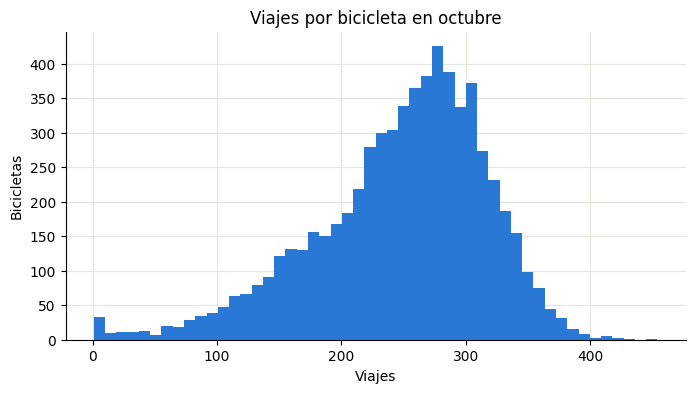

count    6453.0
mean      247.7
std        69.5
min         1.0
25%       209.0
50%       259.0
75%       296.0
max       454.0
Name: count, dtype: float64

In [28]:
viajes_por_bici = viajes_validos["Bici"].value_counts()
print(f"Bicis distintas en octubre: {viajes_por_bici.size:,}")

fig, ax = plt.subplots(figsize=(8, 4))
viajes_por_bici.plot.hist(bins=50, ax=ax)
ax.set(title="Viajes por bicicleta en octubre", xlabel="Viajes", ylabel="Bicicletas")
plt.show()

viajes_por_bici.describe().round(1)

# Analísis segmentado

### TO Dos:
- Hacer clustering basado en uso y geografia 
- Seccionar estaciones de interes 
	- (Tal vez enfoque en el sur de la ciudad para expandir ecobici, basado en infraestructura existente, o no)
- Cadenas de markov M/M/C/ sobre las estaciones de interes
	- Investigar a fondo estas estaciones y su capacidad
	- ...
- Proponer redistribucion de ecobicis 
